# A/B/C 가용성과 이벤트 보존

실제 V3 원본 인덱스와 집계만 사용합니다. 원본·V1/V2는 읽기 전용입니다. 대시보드는 `dashboard/app.py`로 실행합니다.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.common import TABLES, CFG
from src.detail import get_detail
from src.visuals import detail_figure
assert Path(sys.executable).resolve() == Path(CFG['python']).resolve()
print('실제 실행 Python:', sys.executable)
print('시간: raw / 연구 진단용 / 모델 학습 없음')


실제 실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
시간: raw / 연구 진단용 / 모델 학습 없음


In [2]:
features = pd.read_parquet(TABLES/'feature_availability_summary.parquet')
selection = features.policy.eq('conservative') & features.H.eq(600) & features.fault_type.eq('any')
display(features[selection].groupby(['cohort','feature_set'])[['available_anchors','positive_anchors','positive_events']].sum())

available_anchors  positive_anchors  positive_events
cohort  feature_set                                                      
common  A                      1573310              2093              296
        B                      1573310              2093              296
        C                      1573310              2093              296
maximum A                      5522297              3868              503
        B                      3863970              3243              488
        C                      1573310              2093              296

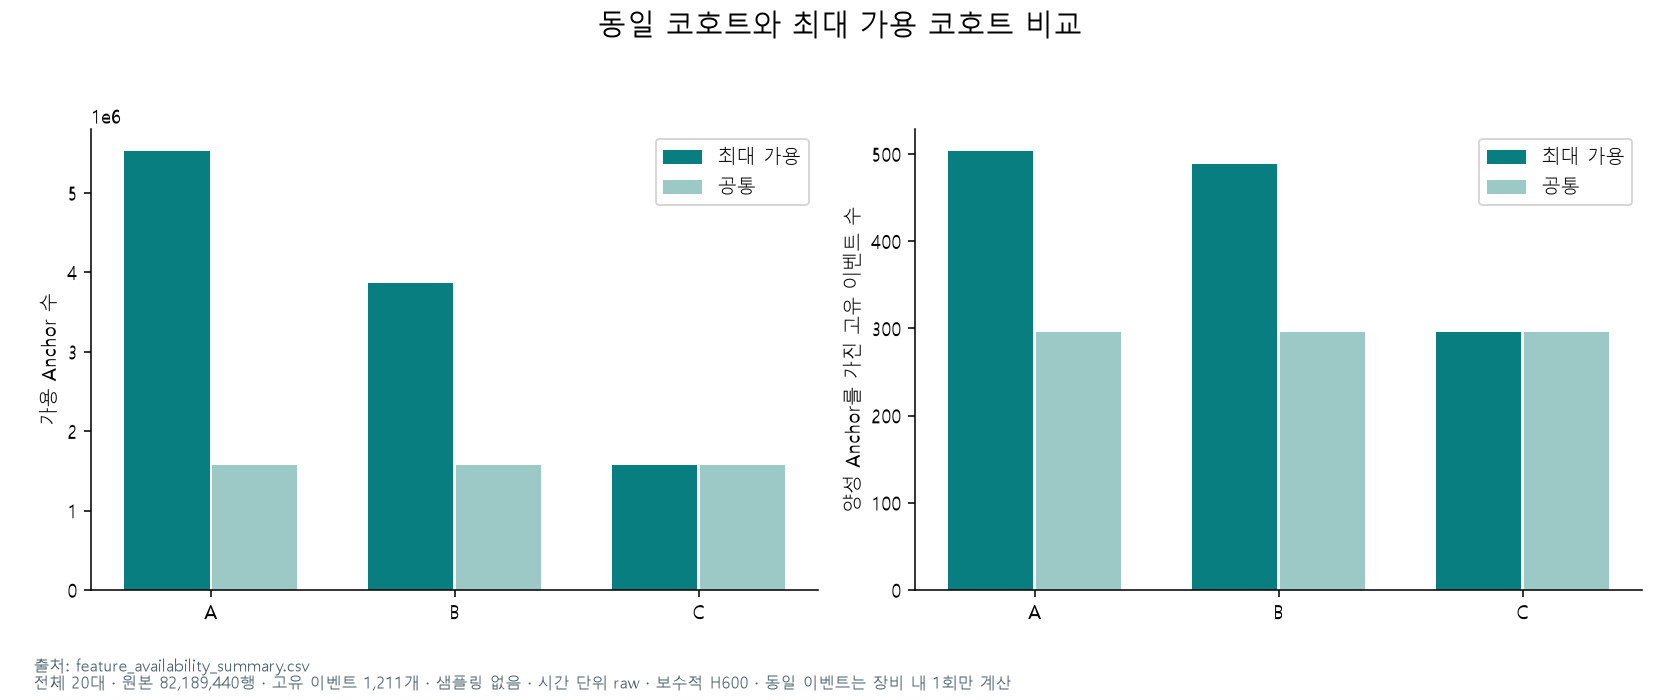

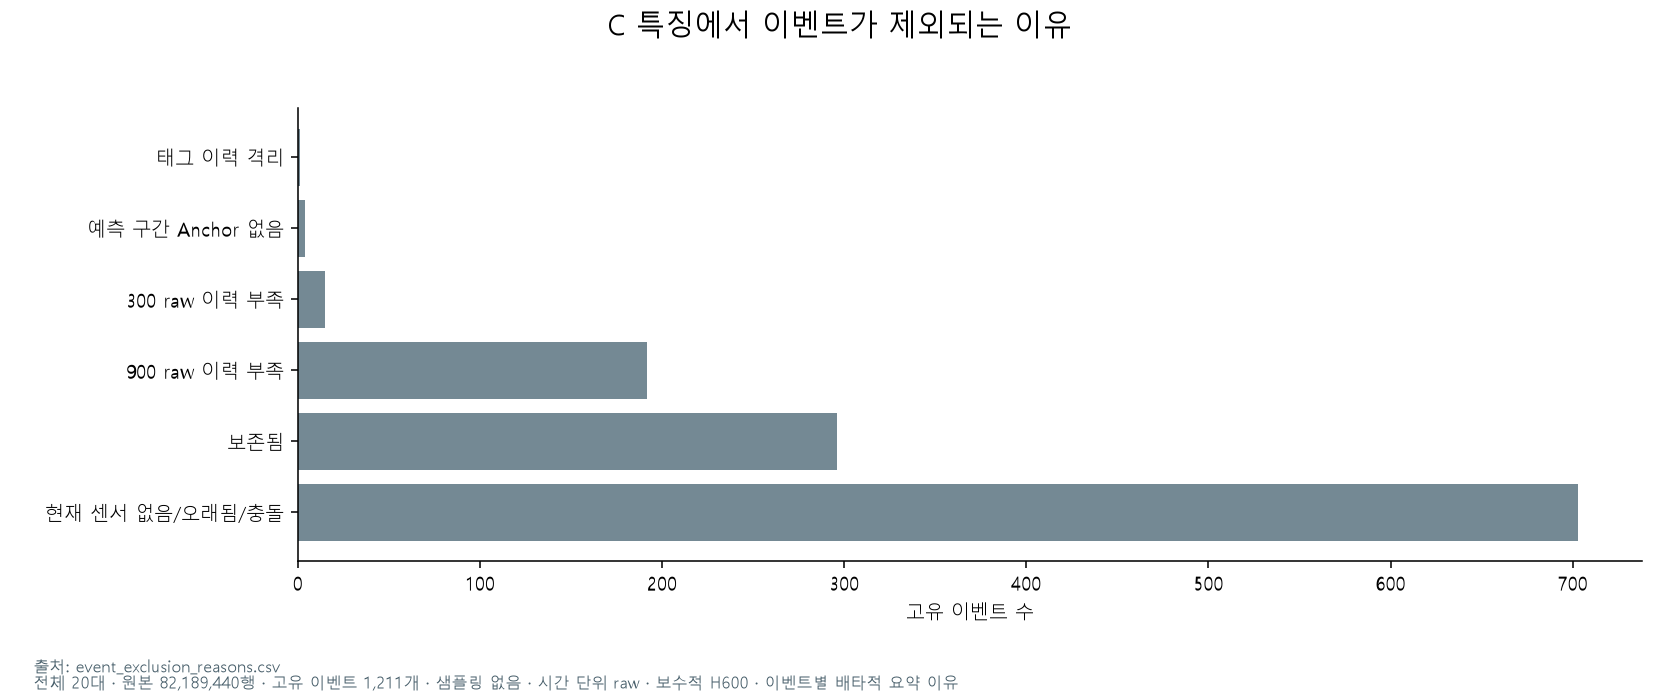

In [3]:
display(Image(filename=str(ROOT/'outputs/figures/feature_availability/cohorts.png')))
display(Image(filename=str(ROOT/'outputs/figures/event_preservation/exclusion_reasons.png')))

In [4]:
reasons = pd.read_parquet(TABLES/'event_exclusion_reasons.parquet')
display(reasons[reasons.Tool.eq('03M02') & reasons.policy.eq('conservative') & reasons.H.eq(600) & reasons.feature_set.eq('C')].head(20))
display(Markdown('공통 코호트와 최대 가용 코호트를 구분합니다. 특징 수가 많다는 사실만으로 성능이 좋다고 판단하지 않습니다.'))

,event_id,Tool,fault_type,fault_time,policy,H,feature_set,warning_anchors,label_positive_anchors,usable_positive_anchors,current_available,history_60,history_300,history_900,imminent_excluded,preserved,reason
7241,03M02-low-c37936a41279,03M02,low,3326152.0,conservative,600,C,9,9,0,0,0,0,0,0,False,현재 센서 없음/오래됨/충돌
7268,03M02-low-a541bb296b11,03M02,low,3780688.0,conservative,600,C,9,9,0,0,0,0,0,0,False,현재 센서 없음/오래됨/충돌
7295,03M02-low-a415501ca67e,03M02,low,3961378.0,conservative,600,C,9,9,5,5,5,5,5,0,True,보존됨
7322,03M02-low-fa2c15592d5a,03M02,low,4528896.0,conservative,600,C,9,9,0,0,0,0,0,0,False,현재 센서 없음/오래됨/충돌
7349,03M02-high-7ba2d4a006ee,03M02,high,4984318.0,conservative,600,C,9,9,0,0,0,0,0,0,False,현재 센서 없음/오래됨/충돌
7376,03M02-low-5dceeb25452b,03M02,low,5076390.0,conservative,600,C,9,9,0,0,0,0,0,0,False,현재 센서 없음/오래됨/충돌
7403,03M02-low-d58f88774e8e,03M02,low,5120600.0,conservative,600,C,9,9,0,5,5,2,0,0,False,900 raw 이력 부족
7430,03M02-high-30905f1e029f,03M02,high,5128078.0,conservative,600,C,9,9,9,9,9,9,9,0,True,보존됨
7457,03M02-high-f040fbec61b0,03M02,high,6040840.0,conservative,600,C,9,9,0,0,0,0,0,0,False,현재 센서 없음/오래됨/충돌
7484,03M02-low-92ee94b49a7e,03M02,low,6052526.0,conservative,600,C,9,9,0,0,0,0,0,0,False,현재 센서 없음/오래됨/충돌


공통 코호트와 최대 가용 코호트를 구분합니다. 특징 수가 많다는 사실만으로 성능이 좋다고 판단하지 않습니다.